Algoritmos Genéticos y Optimización Heurística - UTN-FRT
# **Trabajo Práctico N°3** 
##**Tema**: Operadores Genéticos##

Integrantes: Breslauer - Perez

## Ejercicio 1
Implemente el operador de selección con Ruleta con pesos, completando el código dado.

In [1]:
import random

def sel_ruleta(F, cant_selectos, eps):
    """ Operador de selección por ruleta con pesos.
    Parametros:
    F: list
        Lista de valores de fitness de cada individuo de la población.
    cant_selectos: int
        Cantidad de individuos a seleccionar.
    eps: float
        Valor de fitness normalizado para el peor individuo.
    S: list
        Lista con las POSICIONES de los individuos seleccionados.
    """
    # 1) Normalizar el fitness: el peor individuo queda con valor eps (> 0),
    #    así todos tienen alguna chance y funciona con fitness negativos.
    min_f = min(F)
    f_norm = [fi - min_f + eps for fi in F]

    # 2) Probabilidad de cada individuo, proporcional a su fitness normalizado
    total = sum(f_norm)
    prob = [fi / total for fi in f_norm]

    # 3) Probabilidades acumuladas (los "sectores" de la ruleta)
    acum = []
    s = 0
    for p in prob:
        s += p
        acum.append(s)
    acum[-1] = 1.0  # evita errores de redondeo

    # 4) Girar la ruleta cant_selectos veces
    S = []
    for _ in range(cant_selectos):
        r = random.random()
        for i, a in enumerate(acum):
            if r <= a:
                S.append(i)
                break

    return S #se debe devolver una lista de tamaño "cant_selectos"

# PRUEBA

F = [0.54, 0.28, 0.16, 0.12]
eps = 0.2
cant_tiros = 5

#aplicar seleccion
sel = sel_ruleta(F, cant_tiros, eps)

print('Posicion de individuos seleccionados:')
print(sel)


Posicion de individuos seleccionados:
[0, 0, 0, 0, 0]


## Ejercicio 2
Genere un histograma que muestre la probabilidad de ser seleccionado de cada individuo (basado en su fitness), y un histograma con la cantidad de veces que cada individuo es efectivamente seleccionado. Utilice una población con 10 individuos y el operador de seleccion implementado en el punto anterior sobre la función de evaluación f(x,y) = -sum(x^2 + y^2). ¿Qué diferencia hay al seleccionar 10, 100 y 1000 tiros con el operador dado?

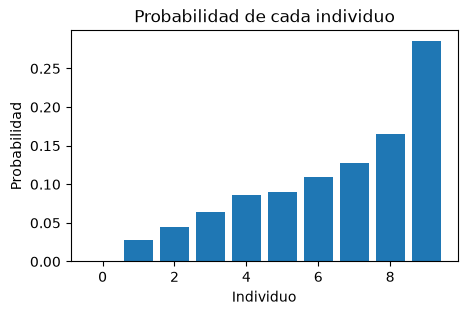

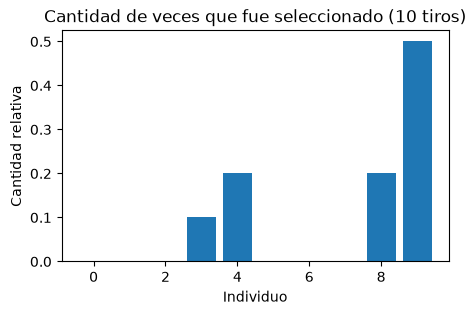

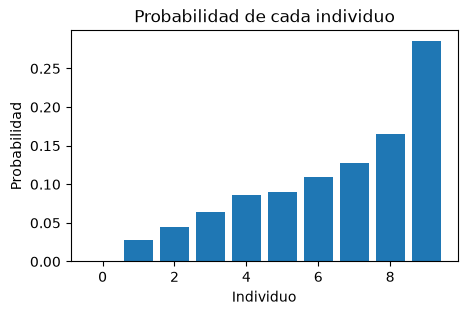

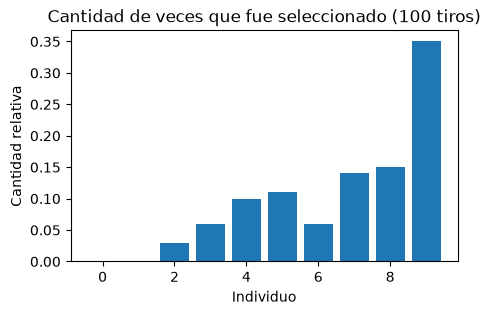

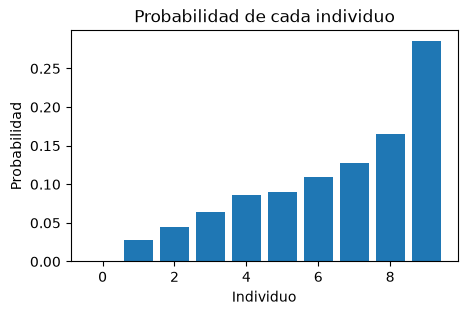

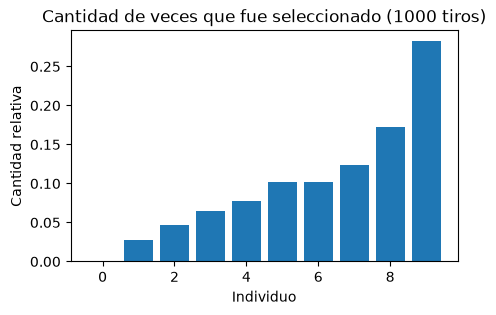

In [2]:
import random
import matplotlib.pyplot as plt

def histograma(pop, fitness, p_selectos, eps):
    #estimo probabilidad de cada individuo de ser seleccionado
    min_f = min(fitness)
    f_norm = [fi - min_f + eps for fi in fitness]
    sum_f = sum(f_norm)
    prob = [fi / sum_f for fi in f_norm]
    
    #obtener cantidad relativa de soluciones obtenidas
    c = [0] * len(prob)
    for p in p_selectos:
        c[p] = c[p] + 1
    cant = [ci / len(p_selectos) for ci in c]

    #obtengo el orden en el que voy a graficar
    psort = sorted(range(len(prob)), key=lambda k: prob[k])

    #mostrar graficas
    plt.figure()
    plt.bar(range(len(prob)), [prob[p] for p in psort])
    plt.title('Probabilidad de cada individuo')
    plt.xlabel('Individuo')
    plt.ylabel('Probabilidad')

    plt.figure()
    plt.bar(range(len(cant)), [cant[p] for p in psort])
    plt.title('Cantidad de veces que fue seleccionado')
    plt.xlabel('Individuo')
    plt.ylabel('Cantidad relativa')

def generar_poblacion(bounds, cant_soluciones):
    pop = []
    for i in range(cant_soluciones):
        s = [random.random() * (b[1] - b[0]) + b[0] for b in bounds]
        pop.append(s)
    return pop

def fitness(S):
    return -sum([xi**2 for xi in S])

plt.rcParams['figure.figsize'] = (5, 3)

# PRUEBA
random.seed(1)

cant_soluciones = 10
cant_tiros = 10
eps = 0.1
bounds = [[0,10], [0,10]] #2 coordenadas 

#generar una poblacion de individuos de prueba
pop = generar_poblacion(bounds, cant_soluciones)
#evaluar cada individuo
F = [fitness(s) for s in pop]
#aplicar seleccion con 10, 100 y 1000 tiros sobre la MISMA poblacion
for cant_tiros in [10, 100, 1000]:
    sel = sel_ruleta(F, cant_tiros, eps)
    histograma(pop, F, sel, eps)
    plt.title(f'Cantidad de veces que fue seleccionado ({cant_tiros} tiros)')
plt.show()


**Respuesta:** el primer histograma (probabilidad) es el mismo en los tres casos, porque depende solo del fitness de cada individuo: los que están más cerca de (0,0) tienen mayor probabilidad. Lo que cambia es la frecuencia real de selección:

- **10 tiros:** la distribución es muy irregular. Algunos individuos con buena probabilidad pueden no salir nunca y otros malos salir más de lo esperado. Hay mucho ruido estocástico.
- **100 tiros:** la forma del histograma ya se parece a la de las probabilidades, aunque con desvíos visibles.
- **1000 tiros:** la frecuencia relativa converge a la probabilidad teórica (ley de los grandes números) y ambos histogramas son casi iguales.

Conclusión: la ruleta respeta las probabilidades solo en promedio. Con pocos tiros, como en una población chica, la selección tiene mucha varianza, lo que puede hacer perder buenos individuos (deriva genética).

## Ejercicio 3
Implemente el operador Uniform crossover, completando el código. Luego apliquelos a los dos individuos dados.

In [3]:
import random

def xov_uniform(P1, P2):
    """Operador Uniform Crossover para Algoritmos Geneticos.
    Parametros:
    P1: list
        Lista correspondiente a uno de los individuos padres a cruzar.
    P2: list
        Lista correspondiente a uno de los individuos padres a cruzar.
    """
    C1, C2 = [], []
    # Para cada gen se tira una moneda: con prob. 0.5 los hijos lo heredan
    # tal cual de sus padres, si no, se intercambian.
    for g1, g2 in zip(P1, P2):
        if random.random() < 0.5:
            C1.append(g1)
            C2.append(g2)
        else:
            C1.append(g2)
            C2.append(g1)

    return C1, C2 #devolver listas del mismo tamaño que P1 y P2

P1 = [2.1, 9.3, 7.4, 1.8, 5.2]
P2 = [4.2, 1.6, 2.7, 6.4, 5.9]
print("Individuos Padres")
print(P1)
print(P2)

C1, C2 = xov_uniform(P1, P2)
print("Uniform Crossover")
print(C1)
print(C2)


Individuos Padres
[2.1, 9.3, 7.4, 1.8, 5.2]
[4.2, 1.6, 2.7, 6.4, 5.9]
Uniform Crossover
[2.1, 1.6, 7.4, 6.4, 5.9]
[4.2, 9.3, 2.7, 1.8, 5.2]


## Ejercicio 4
Implemente los siguientes operadores de mutación completando el código dado.
1. Boundary Mutation
2. Step Mutation

In [4]:
import random

def mut_boundary(P, Bounds):
    """Boundary Mutation
    Parámetros
    P: list
        Vector correspondiente a un individuo.
    Bounds: list
        Matriz que indica los valores maximo y minimo de cada coordenada.
    """
    C = P.copy()
    cut = random.randint(0, len(P)-1)
    # la coordenada elegida pasa a valer su limite inferior o superior
    C[cut] = Bounds[cut][random.randint(0, 1)]
    return C

def mut_step(P, Bounds, paso=0.1):
    """Step Mutation
    Parámetros
    P: list
        Vector correspondiente a un individuo.
    Bounds: list
        Matriz que indica los valores maximo y minimo de cada coordenada.
    paso: float
        Tamaño máximo del paso, como fracción del rango de la coordenada.
    """
    C = P.copy()
    # se elige una coordenada al azar
    i = random.randint(0, len(P)-1)
    lo, hi = Bounds[i]
    # se le suma un paso pequeño, positivo o negativo
    delta = random.uniform(-1, 1) * paso * (hi - lo)
    # se recorta para no salir de los limites
    C[i] = min(max(C[i] + delta, lo), hi)

    return C #devolver lista del mismo tamaño que P

P = [2.1, 9.3, 7.4, 1.8, 5.2]
bounds = [[0,10], [0,10], [0,10], [0,10], [0,10]]

print("Individuo original")
print(P)

C = mut_boundary(P, bounds)
print("Boundary Mutation")
print(C)

C = mut_step(P, bounds)
print("Step Mutation")
print(C)


Individuo original
[2.1, 9.3, 7.4, 1.8, 5.2]
Boundary Mutation
[2.1, 9.3, 7.4, 1.8, 0]
Step Mutation
[2.1, 9.3, 7.4, 1.8, 6.104670477057969]
